In [1]:
%load_ext autoreload
%autoreload 2


In [3]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from bgflow.utils import (assert_numpy, distance_vectors, distances_from_vectors, 
                          remove_mean, IndexBatchIterator, LossReporter, as_numpy, compute_distances
)
from bgflow import (GaussianMCMCSampler, DiffEqFlow, BoltzmannGenerator, Energy, Sampler, 
                    MultiDoubleWellPotential, MeanFreeNormalDistribution, KernelDynamics, 
                    BlackBoxDynamics, TimeIndependentDynamics, DenseNet)
from bgflow.bg import sampling_efficiency
import ot as pot
import tqdm
from eq_ot_flow.models import EGNN_dynamics_AD2_cat
from eq_ot_flow.utilities import superpose_points, superpose_points_batch, plot_flowpath_trajectory, plot_flowpath_trajectory_3d
from eq_ot_flow.estimator import BruteForceEstimatorFast
from eq_ot_flow.LJ import LennardJonesPotential
from scipy.optimize import linear_sum_assignment
from torchdyn.core import NeuralODE

from bgmol.datasets import AImplicitUnconstrained
import mdtraj as md
from scipy.stats import vonmises
from matplotlib.colors import LogNorm


In [8]:
#dataset = AImplicitUnconstrained(download=True, read=True)
dataset = AImplicitUnconstrained(read=True)
n_particles = 22
n_dimensions = 3
dim = n_particles * n_dimensions

Using downloaded and verified file: /tmp/A.pdb


In [ ]:
target = dataset.get_energy_model()


In [18]:
ala_traj = md.Trajectory(dataset.xyz, dataset.system.mdtraj_topology)

atom_dict = {"H": 0, "C":1, "N":2, "O":3}
atom_types = []
for atom_name in ala_traj.topology.atoms:
    atom_types.append(atom_name.name[0])
atom_types = np.array([atom_dict[atom_type] for atom_type in atom_types])

In [ ]:
# Make the backbone atoms distingushiable
atom_types[[4,6,8,14,16]] = np.arange(4, 9)

In [22]:
h_initial = torch.nn.functional.one_hot(torch.tensor(atom_types))


tensor([[0, 1, 0, 0, 0, 0, 0, 0, 0],
        [1, 0, 0, 0, 0, 0, 0, 0, 0],
        [1, 0, 0, 0, 0, 0, 0, 0, 0],
        [1, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 1, 0, 0, 0, 0],
        [0, 0, 0, 1, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 1, 0, 0, 0],
        [1, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 1, 0, 0],
        [1, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 1, 0, 0, 0, 0, 0, 0, 0],
        [1, 0, 0, 0, 0, 0, 0, 0, 0],
        [1, 0, 0, 0, 0, 0, 0, 0, 0],
        [1, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 1, 0],
        [0, 0, 0, 1, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 1],
        [1, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 1, 0, 0, 0, 0, 0, 0, 0],
        [1, 0, 0, 0, 0, 0, 0, 0, 0],
        [1, 0, 0, 0, 0, 0, 0, 0, 0],
        [1, 0, 0, 0, 0, 0, 0, 0, 0]])

In [ ]:
scaling = 10
data_smaller = torch.from_numpy(np.load("data/AD2_relaxed.npy")).float()/10
data_smaller = remove_mean(data_smaller, n_particles, n_dimensions).reshape(-1, dim) * scaling

In [27]:
data_smaller.shape

torch.Size([100000, 66])

In [28]:
kappa = 10

ala_traj = md.Trajectory(data_smaller.cpu().numpy().reshape(-1, n_particles, n_dimensions), dataset.system.mdtraj_topology)
phi = md.compute_phi(ala_traj)[1].flatten()
psi = md.compute_psi(ala_traj)[1].flatten()


(660, torch.Size([100000, 66]))

In [31]:
weights=150*vonmises.pdf(phi-1., kappa)+1
pos_phi = ((phi>0) & (phi<2)) 
weights[pos_phi].sum(), weights[~pos_phi].sum()

(103005.78590610535, 99337.16249923782)

In [33]:
data_smaller_weighted_idx = np.random.choice(np.arange(len(data_smaller)), len(data_smaller), p=weights/weights.sum(), replace=True)

In [34]:
data_smaller_weighted = data_smaller[data_smaller_weighted_idx]

In [37]:
# now set up a prior
prior =  MeanFreeNormalDistribution(dim, n_particles, two_event_dims=False).cuda()


In [41]:
# Build the Boltzmann Generator

net_dynamics = EGNN_dynamics_AD2_cat(n_particles=n_particles, device='cuda',  n_dimension=dim // n_particles,h_initial=h_initial, hidden_nf=64,
    act_fn=torch.nn.SiLU(), n_layers=5, recurrent=True, tanh=True, attention=True, condition_time=True, mode='egnn_dynamics', agg='sum')


bb_dynamics = BlackBoxDynamics(
    dynamics_function=net_dynamics,
    divergence_estimator=BruteForceEstimatorFast()
)
flow = DiffEqFlow(
    dynamics=bb_dynamics
)
# having a flow and a prior, we can now define a Boltzmann Generator

bg = BoltzmannGenerator(prior, flow, target).cuda()

In [46]:
# train with convex mixture of NLL and KL loss

n_batch = 256
batch_iter = IndexBatchIterator(len(data_smaller), n_batch)

optim = torch.optim.Adam(bg.parameters(), lr=5e-4)

n_epochs = 1000
n_report_steps = 5


reporter = LossReporter("NLL")
#val_losses = []

In [48]:
# start with 5e-4 for 1000
# 5e-5 for 1000

## Note, in practice the batch reordering should not be done during training

In [ ]:
sigma = 0.01
for epoch in range(n_epochs):
    for it, idxs in enumerate(batch_iter):

        optim.zero_grad()
        x1 = data_smaller[idxs].cuda()
        batchsize = x1.shape[0]
        t = torch.rand(batchsize, 1).cuda()
        x0 = prior.sample(batchsize)

        # Resample x0, x1 according to transport matrix
        a1, b1 = pot.unif(x0.size()[0]), pot.unif(x1.size()[0])
        M = torch.cdist(x0, x1) ** 2
        M = M / M.max()
        pi = pot.emd(a1, b1, M.detach().cpu().numpy())
        # Sample random interpolations on pi
        p = pi.flatten()
        p = p / p.sum()
        choices = np.random.choice(pi.shape[0] * pi.shape[1], p=p, size=batchsize)
        i, j = np.divmod(choices, pi.shape[1])
        x0 = x0[i]
        x1 = x1[j]
        # calculate regression loss
        mu_t = x0 * (1 - t) + x1 * t
        sigma_t = sigma
        noise = prior.sample(batchsize)
        x = mu_t + sigma_t * noise
        ut = x1 - x0
        vt = bg.flow._dynamics._dynamics._dynamics_function(t, x)
        loss = torch.mean((vt - ut) ** 2)
        loss.backward()
        optim.step()
        reporter.report(loss)

        if it % n_report_steps == 0:
            print("\repoch: {0}, iter: {1}/{2}, loss: {3:.4}".format(
                    epoch,
                    it,
                    len(batch_iter),
                    *reporter.recent(1).ravel()
                ), end="")

/storage/mi/leoma/libraries/en_flows_code/egnn/models2.py:195: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  t = torch.tensor(t).to(xs)


epoch: 295, iter: 110/390, loss: 1.0583

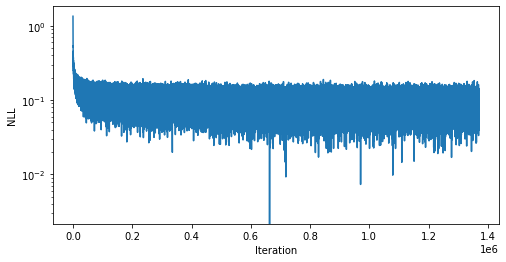

In [96]:
reporter.plot(log=True)

In [ ]:
# PATH = "models/alanine_weighted_OT_flow_matching"


# checkpoint = torch.load(PATH_last)
# flow.load_state_dict(checkpoint['model_state_dict']), optim.load_state_dict(checkpoint['optimizer_state_dict'])


In [52]:
# use OTD in the evaluation process
bb_dynamics._divergence_estimator = brute_force_estimator_fast
bg.flow._integrator_atol = 1e-5
bg.flow._integrator_rtol = 1e-5
flow._use_checkpoints = False
flow._kwargs = {}

In [ ]:
import tqdm

n_samples = 200
n_sample_batches = 500
latent_np = np.empty(shape=(0))
samples_np = np.empty(shape=(0))
log_w_np = np.empty(shape=(0))
dlogp_np = np.empty(shape=(0))
#energies_np = np.empty(shape=(0))
distances_x_np = np.empty(shape=(0))

for i in tqdm.tqdm(range(n_sample_batches)):
    with torch.no_grad():
        samples, latent, dlogp = bg.sample(n_samples, with_latent=True, with_dlogp=True)
        #latent = latent[0]
        #log_weights = bg.log_weights_given_latent(samples, latent, dlogp).detach().cpu().numpy()
        latent_np = np.append(latent_np, latent.detach().cpu().numpy())
        samples_np = np.append(samples_np, samples.detach().cpu().numpy())
        distances_x = distances_from_vectors(distance_vectors(samples.view(-1, n_particles, n_dimensions))).detach().cpu().numpy().reshape(-1)
        distances_x_np = np.append(distances_x_np, distances_x)

        #log_w_np = np.append(log_w_np, log_weights)
        dlogp_np = np.append(dlogp_np, as_numpy(dlogp))
        #energies = target.energy(samples/scaling).detach().cpu().numpy()
        #energies_np = np.append(energies_np, energies)
        

latent_np = latent_np.reshape(-1, dim)
samples_np = samples_np.reshape(-1, dim)

In [56]:
latent_np = latent_np.reshape(-1, dim)
samples_np = samples_np.reshape(-1, dim)

In [92]:
from bgflow import XTBEnergy, XTBBridge
import openmm as mm
atom_dict = {"H": 0, "C":1, "N":2, "O":3}
atom_types_xtb = []
for atom_name in ala_traj.topology.atoms:
    atom_types_xtb.append(atom_name.name[0])
atom_types_xtb = np.array([atom_dict[atom_type] for atom_type in atom_types_xtb])

temperature = 300
number_dict = {0: 1, 1:6, 2:7, 3:8}
numbers = np.array([number_dict[atom_type] for atom_type in atom_types_xtb])
target_xtb = XTBEnergy(
    XTBBridge(numbers=numbers, temperature=temperature, solvent="water"),
    two_event_dims=False
)

In [100]:
energies_np = as_numpy(target_xtb.energy(torch.from_numpy(samples_np)/scaling))

latent_energies = prior.energy(torch.from_numpy(latent_np).cuda())

In [105]:
energy_offset = 34600
energies_np += energy_offset

In [106]:
data_holdout_xtb = torch.from_numpy(np.load("data/AD2_relaxed_holdout.npy")).reshape(-1, 66)
energies_data_holdout = target_xtb.energy(data_holdout_xtb[::9]/scaling)
energies_data_holdout += energy_offset

In [112]:
log_w_np = -as_numpy(energies_np).reshape(-1,1) + as_numpy(latent_energies) + dlogp_np.reshape(-1,1)

In [114]:
energies_np = energies_np[np.isfinite(log_w_np).flatten()]
samples_np_plot = samples_np[np.isfinite(log_w_np).flatten()]
log_w_np = log_w_np[np.isfinite(log_w_np)]

In [115]:
sampling_efficiency(torch.from_numpy(log_w_np)).item()

0.003468569933906407

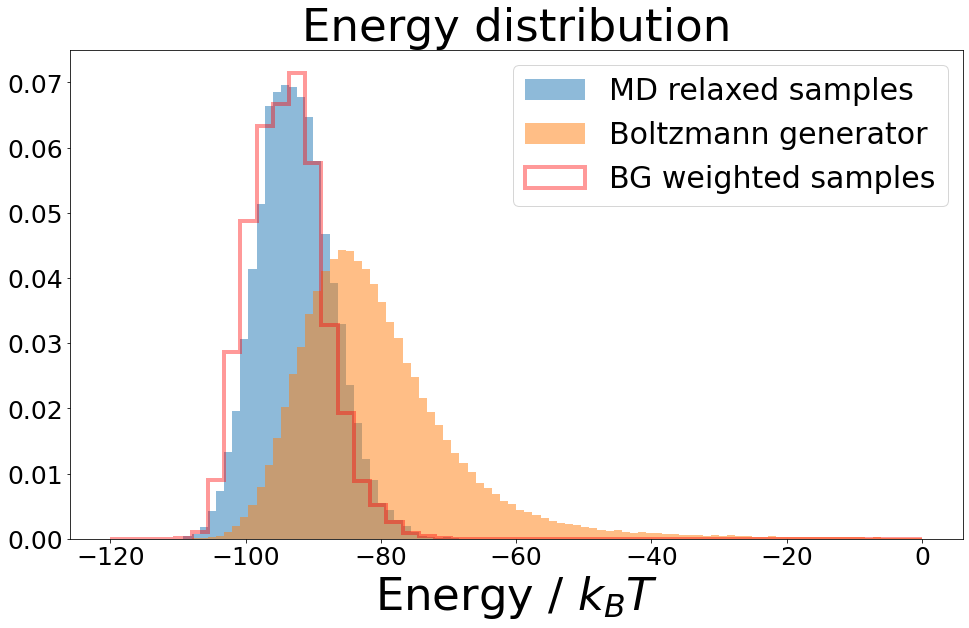

In [121]:
plt.figure(figsize=(16,9))

plt.hist(as_numpy(energies_data_holdout), bins=100, alpha=0.5, density=True, label="MD relaxed samples", range=(-120, 0));
#plt.hist(energies_np, bins=100,range=(-34710, -34610) ,alpha=0.5, density=True, label="BG");
plt.hist(energies_np, bins=100,range=(-120, 0) ,alpha=0.5, density=True, label="Boltzmann generator");
plt.hist(energies_np.reshape(-1), bins=50, density=True,  range=(-120, 0), alpha=0.4, histtype='step', linewidth=4,
         color="r", label="BG weighted samples", weights=np.exp(log_w_np));
plt.xticks(fontsize=25) 
plt.yticks(fontsize=25);
plt.legend(fontsize=30);
plt.xlabel(r"Energy / $k_B T$", fontsize=45)  
plt.title("Energy distribution", fontsize=45);


In [124]:
# carbon atoms
carbon_pos = np.where(atom_types==1)[0]
carbon_samples_np = samples_np_plot.reshape(-1, 22, 3)[:, carbon_pos]
carbon_distances = np.linalg.norm(samples_np_plot.reshape(-1, 22, 3)[:, [8]] - carbon_samples_np, axis=-1)
# likely index of c beta atom
cb_idx = np.where(carbon_distances==carbon_distances.min(1, keepdims=True))


def determine_chirality_batch(cartesian_coords_batch):
    # Convert Cartesian coordinates to numpy array
    coords_batch = np.array(cartesian_coords_batch)

    # Check if the shape of the array is (n, 4, 3), where n is the number of chirality centers
    if coords_batch.shape[-2:] != (4, 3):
        raise ValueError("Input should be a batch of four 3D Cartesian coordinates")

    # Calculate the vectors from the chirality centers to the four connected atoms
    vectors_batch = coords_batch - coords_batch[:, 0:1, :]
    #print(vectors_batch)
    # Calculate the normal vectors of the planes formed by the three vectors for each chirality center
    normal_vectors_batch = np.cross(vectors_batch[:, 1, :], vectors_batch[:, 2, :])
    #print(normal_vectors_batch)
    # Calculate the dot products of the normal vectors and the vectors from the chirality centers to the fourth atoms
    dot_products_batch = np.einsum('...i,...i->...', normal_vectors_batch, vectors_batch[:, 3, :])
    #print(dot_products_batch)
    # Determine the chirality labels based on the signs of the dot products
    chirality_labels_batch = np.where(dot_products_batch > .000, 'L', 'D')

    return chirality_labels_batch


back_bone_samples = samples_np_plot.reshape(-1, 22, 3)[:, np.array([8,6,14])]
cb_samples = samples_np_plot.reshape(-1, 22, 3)[cb_idx[0], carbon_pos[cb_idx[1]]][:, None, :]
chirality = determine_chirality_batch(np.concatenate([back_bone_samples, cb_samples], axis=1))

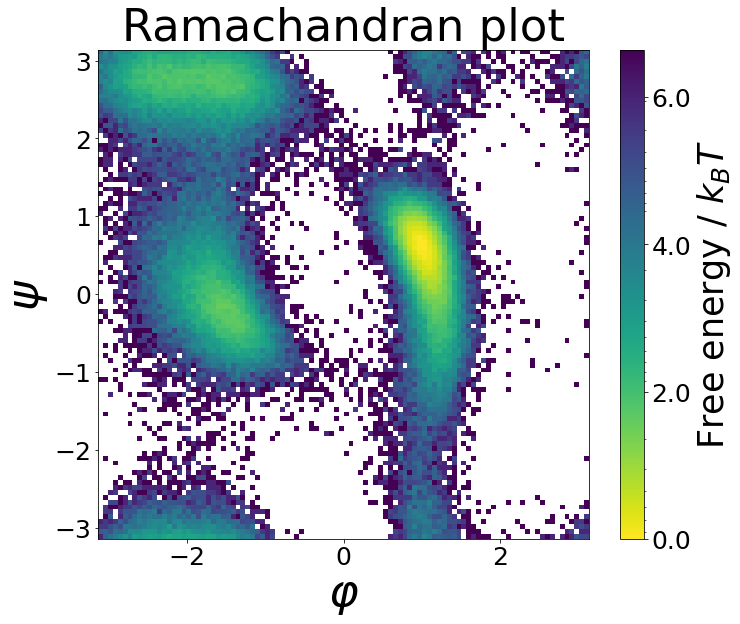

In [126]:
samples_np_mapped = samples_np_plot.copy()
samples_np_mapped[chirality=="D"] *= -1
traj_samples3 = md.Trajectory(samples_np_mapped[energies_np.flatten()<-75].reshape(-1, 22, 3), topology=dataset.system.mdtraj_topology)

phi_indices, psi_indices = [4, 6, 8, 14], [6, 8, 14, 16]
angles = md.compute_dihedrals(traj_samples3, [phi_indices, psi_indices])


plot_range = [-np.pi, np.pi]



fig, ax = plt.subplots(figsize=(11, 9))

h, x_bins, y_bins, im = ax.hist2d(angles[:,0], angles[:,1], 100, norm=LogNorm(), range=[plot_range,plot_range],rasterized=True)
ticks = np.array([np.exp(-6)*h.max(), np.exp(-4)*h.max(),np.exp(-2)*h.max(), h.max()])
ax.set_xlabel(r"$\varphi$", fontsize=45)
ax.set_title("Ramachandran plot", fontsize=45)
ax.set_ylabel(r"$\psi$", fontsize=45)
ax.xaxis.set_tick_params(labelsize=25)
ax.yaxis.set_tick_params(labelsize=25)
cbar = fig.colorbar(im, ticks=ticks)
cbar.ax.set_yticklabels(np.abs(-np.log(ticks/h.max())), fontsize=25)
cbar.ax.invert_yaxis()
cbar.ax.set_ylabel(r"Free energy / $k_B T$", fontsize=35)

In [128]:
def plot_fes(
    samples: np.ndarray,
    bw_method:  None,
    weights: None,
    get_DeltaF: bool = True,
    kBT: float = 1.0,
):
    from scipy.stats import gaussian_kde
    bw_method =0.18# "scott"
    grid = np.linspace(samples.min(), samples.max(), 100)
    fes = -kBT * gaussian_kde(samples, bw_method, weights).logpdf(grid)
    fes -= fes.min()
    #plt.plot(grid, fes)

    return grid, fes

In [ ]:
traj_samples4 = md.Trajectory(samples_np_mapped.reshape(-1, 22, 3), topology=dataset.system.mdtraj_topology)

phi = md.compute_phi(traj_samples4)[1].flatten()
phi_right = phi.copy()
phi_left = phi.copy()
phi_right[phi<0] += 2*np.pi
phi_left[phi>np.pi/2] -= 2*np.pi

In [130]:
npz=np.load("models/ad2_umbrella_sampling_means.npz")
xs=npz["xs"]
f_i_mean=npz["f_i_mean"]
f_i_std=npz["f_i_std"]
        

#plot_fes(phi,bw_method=None, weights=np.exp(log_w_np),get_DeltaF=False)
grid_left, fes_left = plot_fes(phi_left, bw_method=None, weights=np.exp(log_w_np), get_DeltaF=False)
grid_right, fes_right = plot_fes(phi_right, bw_method=None, weights=np.exp(log_w_np), get_DeltaF=False)
middle = 1.1
idx_left = (grid_left>=-np.pi)&(grid_left<middle)
grid_left = grid_left[idx_left]
fes_left = fes_left[idx_left]
idx_right = (grid_right<=np.pi)&(grid_right>middle)
grid_right = grid_right[idx_right]
fes_right = fes_right[idx_right]

plt.figure(figsize=(16,9))
plt.plot(xs, f_i_mean, linewidth=5)
plt.fill_between(xs, f_i_mean - f_i_std, f_i_mean + f_i_std, alpha=0.2)
plt.plot(np.hstack([grid_left, grid_right]), np.hstack([fes_left, fes_right]), linewidth=5, linestyle="--")
